<a href="https://colab.research.google.com/github/kenzuroid-tech/PVCK_Ganjil_2026/blob/main/Week10.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

1. Buka https://colab.research.google.com/. Setelah dipastikan bahwa google Colab terhubung dengan Github Anda, buat notebook baru dan beri nama “Week10.ipynb”. Kemudian import beberapa library dan akses folder yang ada di Drive Anda dengan cara sebagai berikut.

> **Object Detection**

Metode yang digunakan :
1. Template Matching
2. Edge Detection
3. Corner Detection
4. Grid Detection
5. Contour Detection

In [1]:
# import library yang dibutuhkan
import cv2 as cv
import numpy as np
from matplotlib import pyplot as plt

In [2]:
# akses drive
from google.colab import drive

# Accessing My Google Drive
drive.mount('/content/drive')

Mounted at /content/drive


2. Implementasikan 6 metode template matching pada OpenCV dengan menggunakan
gambar cats_and_bunnies.jpg dan cat2_templatejpg.jpg sebagai templatenya.

> **Template Matching**

Menggunakan library openCV :   
**cv.matchTemplate(),** dengan parameter

*   **Image** citra input
*   **templ** template yang dicari, ukurannya tidak boleh lebih besar dari citra input
* **method** metode dari template matching

Jenis metode template matching di opencv

1. TM_SQDIFF
2. TM_SQDIFF_NORMED
3. TM_CCORR
4. TM_CCORR_NORMED
5. TM_CCOEFF
6. TM_CCOEFF_NORMED



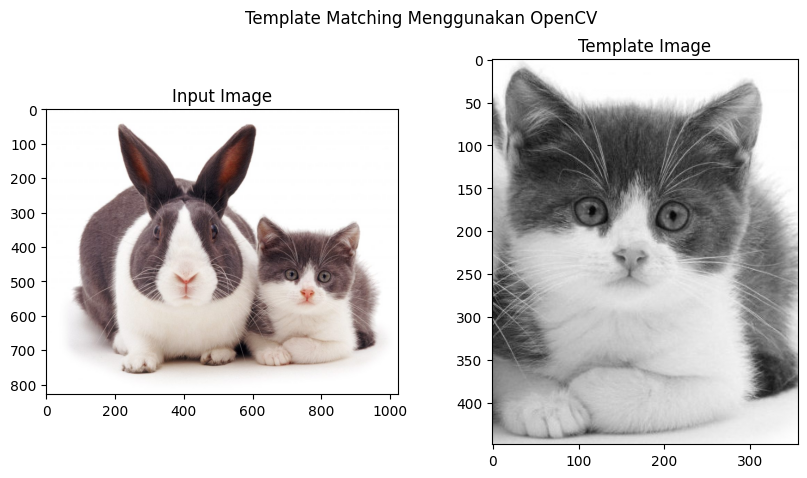

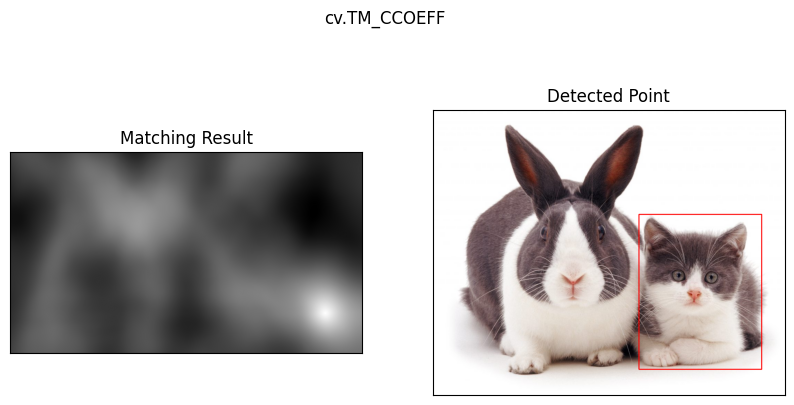

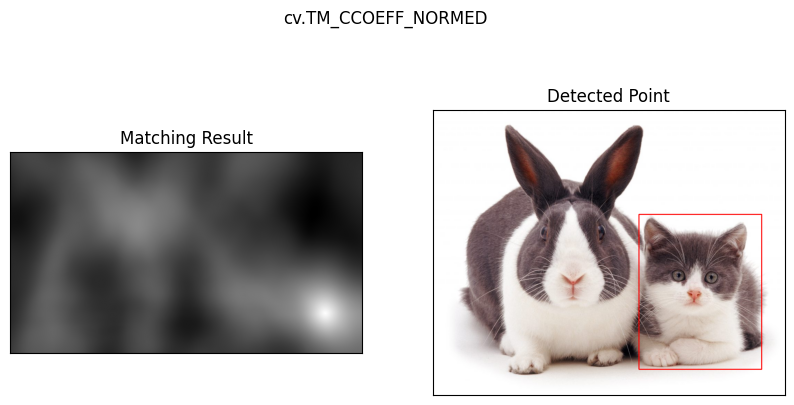

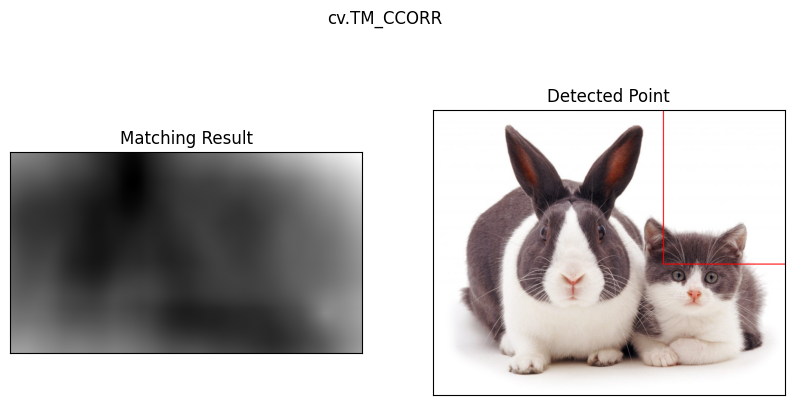

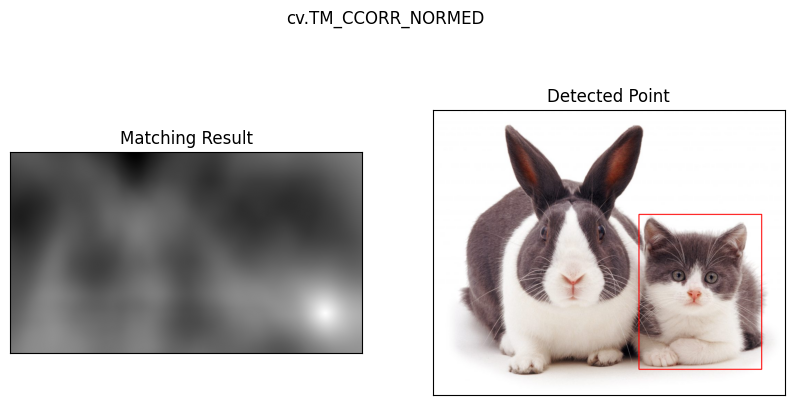

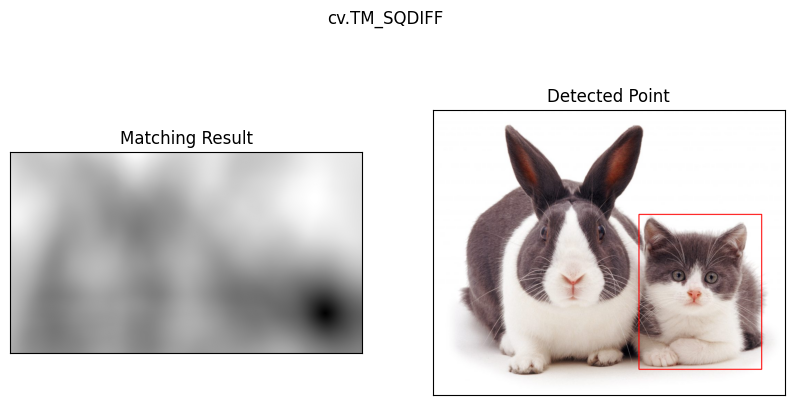

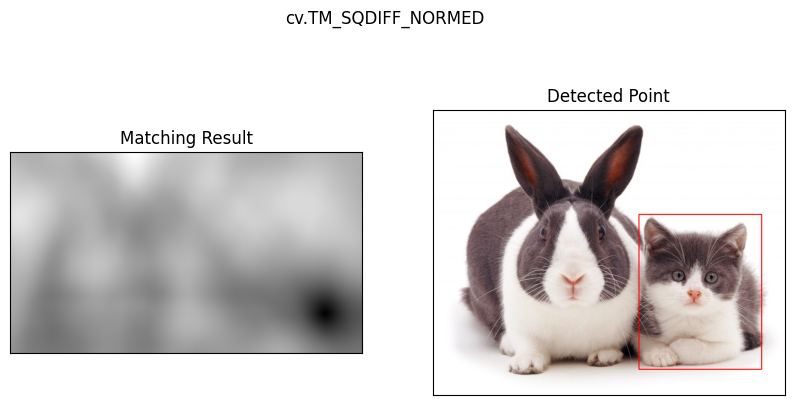

In [5]:
# Template Matching Menggunakan OpenCV
image = cv.imread('/content/drive/MyDrive/PCVK/GAMBAR/cats_and_bunnies.jpg')
image = cv.cvtColor(image, cv.COLOR_BGR2RGB)
image_gray = cv.cvtColor(image, cv.COLOR_BGR2GRAY)
templ = cv.imread('/content/drive/MyDrive/PCVK/GAMBAR/cat2_templatejpg.jpg', 0)
w, h = templ.shape[::-1]

# List metode template matching
methods = ['cv.TM_CCOEFF', 'cv.TM_CCOEFF_NORMED', 'cv.TM_CCORR',
            'cv.TM_CCORR_NORMED', 'cv.TM_SQDIFF', 'cv.TM_SQDIFF_NORMED']

# Menampilkan input image dan template image
plt.figure(figsize = (10,5))
plt.subplot(121),plt.imshow(image)
plt.title('Input Image')
plt.subplot(122),plt.imshow(templ,cmap = 'gray')
plt.title('Template Image')
plt.suptitle("Template Matching Menggunakan OpenCV")
plt.show()

# Loop setiap metode
for meth in methods:
    output_image = image.copy()
    img = image_gray.copy()
    method = eval(meth)
    # Apply template Matching
    res = cv.matchTemplate(img,templ,method)
    min_val, max_val, min_loc, max_loc = cv.minMaxLoc(res)
    # If the method is TM_SQDIFF or TM_SQDIFF_NORMED, take minimum
    if method in [cv.TM_SQDIFF, cv.TM_SQDIFF_NORMED]:
        top_left = min_loc
    else:
        top_left = max_loc
    bottom_right = (top_left[0] + w, top_left[1] + h)
    cv.rectangle(output_image,top_left, bottom_right, (255,0,0), 2)

    plt.figure(figsize = (10,5))
    plt.subplot(1,2,1),plt.imshow(res,cmap = 'gray')
    plt.title('Matching Result'), plt.xticks([]), plt.yticks([])
    plt.subplot(1,2,2),plt.imshow(output_image)
    plt.title('Detected Point'), plt.xticks([]), plt.yticks([])
    plt.suptitle(meth)
    plt.show()

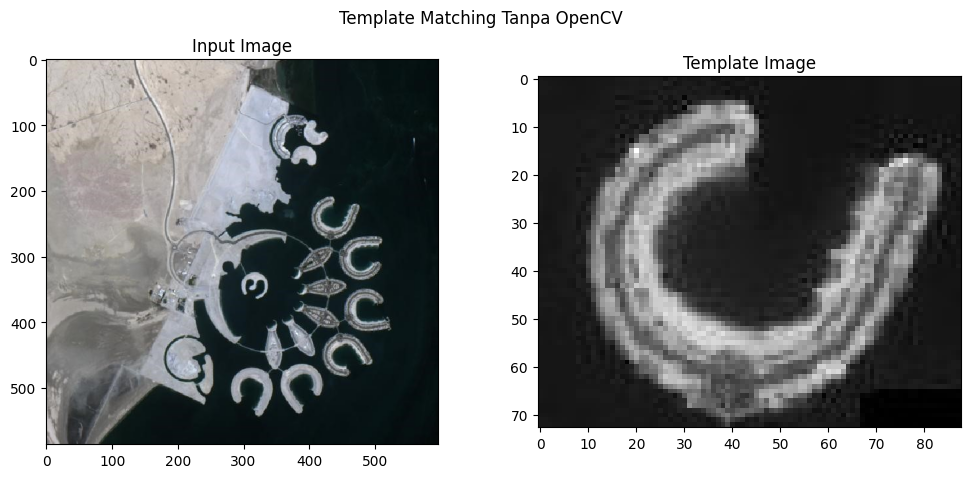

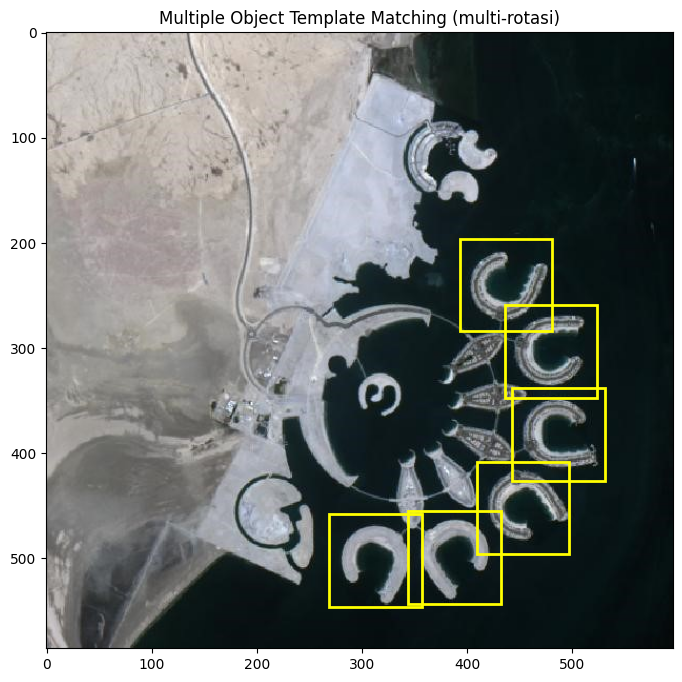

In [12]:
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from scipy.signal import fftconvolve
from scipy.ndimage import rotate, maximum_filter
from matplotlib.patches import Rectangle

image = np.array(Image.open('/content/drive/MyDrive/PCVK/GAMBAR/bahrain.jpg').convert('RGB'))
template = np.array(Image.open('/content/drive/MyDrive/PCVK/GAMBAR/bahrain-template.jpg').convert('L')).astype(float)
image_gray = np.dot(image[..., :3], [0.299, 0.587, 0.114])

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(image)
plt.title('Input Image')
plt.axis('on')

plt.subplot(1, 2, 2)
plt.imshow(template, cmap='gray')
plt.title('Template Image')
plt.axis('on')

plt.suptitle('Template Matching Tanpa OpenCV')
plt.show()

def template_matching(image, template, min_std=25):
    h, w = template.shape
    t = template - template.mean()
    t_norm = np.sqrt(np.sum(t ** 2))

    num = fftconvolve(image, t[::-1, ::-1], mode='valid')
    kernel = np.ones((h, w))
    s  = fftconvolve(image,      kernel, mode='valid')
    s2 = fftconvolve(image ** 2, kernel, mode='valid')
    var = np.maximum(s2 - s ** 2 / (h * w), 0)

    den = t_norm * np.sqrt(var)
    res = np.divide(num, den, out=np.zeros_like(num), where=den > 1e-6)

    # abaikan area datar (tanah kosong, laut polos)
    local_std = np.sqrt(var / (h * w))
    res[local_std < min_std] = 0
    return res

# ---------- parameter ----------
threshold = 0.5
min_std   = 25      # naikkan kalau masih ada false positive di area datar
min_dist  = 60      # jarak minimum antar objek (piksel)
step      = 15      # derajat

H, W = image_gray.shape
th, tw = template.shape
box = max(th, tw)                       # ukuran kotak tetap
bg = np.percentile(template, 10)

score_map = np.full((H, W), -1.0)
angle_map = np.zeros((H, W))

# ---------- gabungkan semua sudut ke peta berbasis PUSAT ----------
for angle in range(0, 360, step):
    t_rot = rotate(template, angle, reshape=True, order=1, mode='constant', cval=bg)
    h, w = t_rot.shape
    res = template_matching(image_gray, t_rot, min_std)

    cy, cx = h // 2, w // 2
    region_s = score_map[cy:cy + res.shape[0], cx:cx + res.shape[1]]
    region_a = angle_map[cy:cy + res.shape[0], cx:cx + res.shape[1]]
    better = res > region_s
    region_s[better] = res[better]
    region_a[better] = angle

# ---------- puncak lokal (otomatis NMS berbasis jarak) ----------
peaks = (score_map == maximum_filter(score_map, size=min_dist)) & (score_map >= threshold)
ys, xs = np.nonzero(peaks)
order = np.argsort(-score_map[ys, xs])
detections = [(xs[i], ys[i], score_map[ys[i], xs[i]], angle_map[ys[i], xs[i]]) for i in order]

# ---------- tampilkan ----------
plt.figure(figsize=(10, 8))
plt.imshow(image)
ax = plt.gca()
for x, y, sc, ang in detections:
    ax.add_patch(Rectangle((x - box/2, y - box/2), box, box,
                           linewidth=2, edgecolor='yellow', facecolor='none'))
plt.title('Multiple Object Template Matching (multi-rotasi)')
plt.show()

4. Implementasikan metode Sobel Edge Detection, Canny Edge Detection, dan Laplacian Edge Detection pada OpenCV dengan menggunakan gambar car-park.jpg, sehingga menghasilkan luaran sebagai berikut:  

*   Sobel Edge Detection
*   Canny Edge Detection
*   Lapclacian Edge Detection





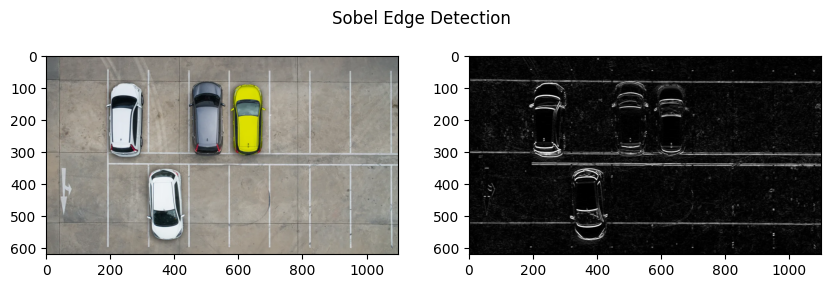

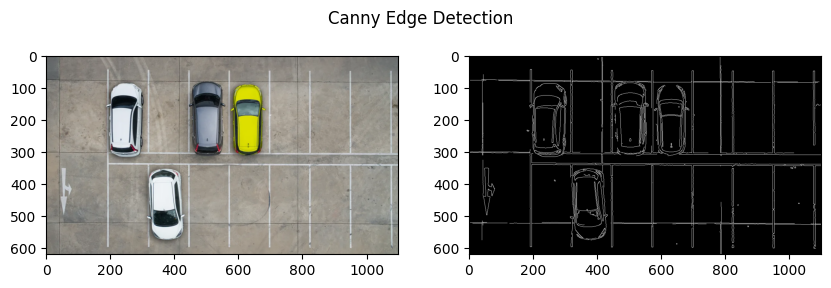

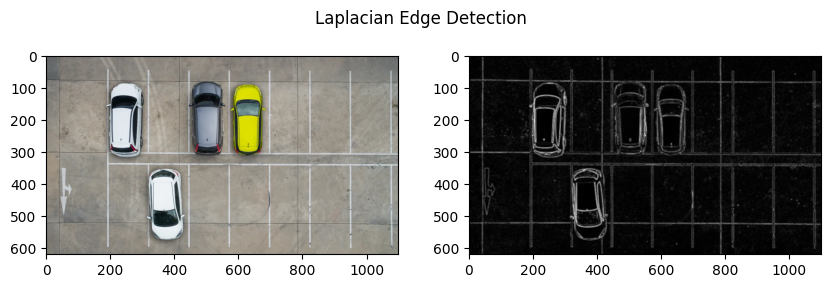

In [14]:
# Edge Detection Menggunakan OpenCV

image = cv.imread('/content/drive/MyDrive/PCVK/GAMBAR/car-park.jpg')
image = cv.cvtColor(image, cv.COLOR_BGR2RGB)
image_gray = cv.cvtColor(image, cv.COLOR_BGR2GRAY)

# remove noise
img = cv.GaussianBlur(image_gray,(3,3),0)
sobel = img.copy()
canny = img.copy()
laplacian = img.copy()
title = ["Sobel Edge Detection", "Canny Edge Detection", "Laplacian Edge Detection"]

# Edge detection menggunakan openCV
sobel = cv.Sobel(src=sobel, ddepth=cv.CV_64F, dx=0, dy=1, ksize=3) # Menggunakan sobel y filter
sobel = cv.convertScaleAbs(sobel) # konversi citra ke uint8
canny = cv.Canny(image=canny, threshold1=100, threshold2=200)
laplacian = cv.Laplacian(laplacian,cv.CV_64F, ksize=3)
laplacian =  cv.convertScaleAbs(laplacian) # konversi citra ke uint8
images = [sobel, canny, laplacian]

for i in range(3):
  plt.figure(figsize = (10,3))
  plt.subplot(121),plt.imshow(image)
  plt.subplot(122),plt.imshow(images[i], 'gray')
  plt.suptitle(title[i])
  plt.show()

5. Implementasikan metode Harris Corner Detection dan Shi-Tomasi Detection pada OpenCV dengan menggunakan gambar chessboard.jpg, sehingga menghasilkan luaran sebagai berikut:

*   Harris Corner Detection
*   Shi-Tomasi Detection



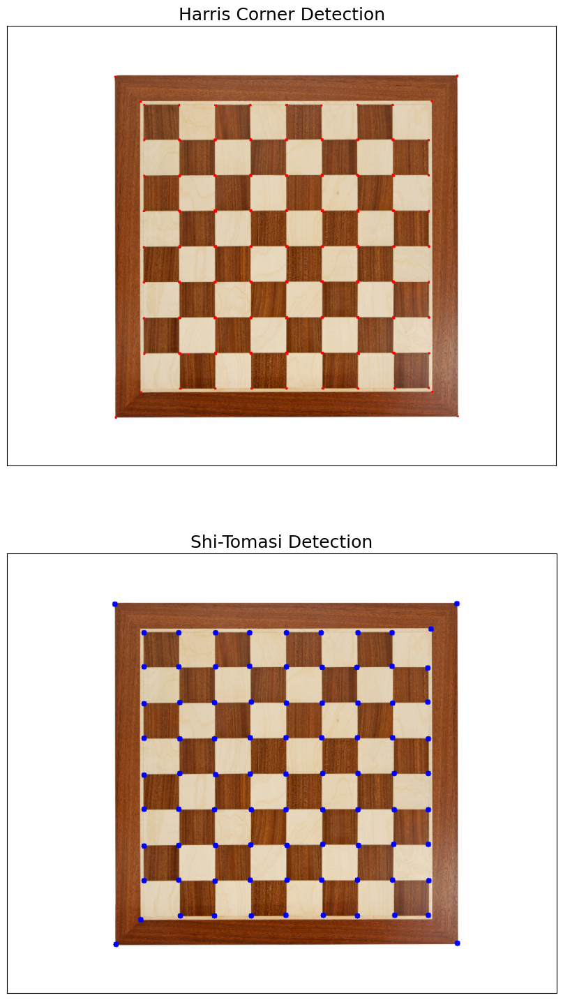

In [17]:
# Implementasi metode Harris Corner Detection dan Shi-Tomasi Detection pada OpenCV
image = cv.imread('/content/drive/MyDrive/PCVK/GAMBAR/chess-board.jpg')
image = cv.cvtColor(image, cv.COLOR_BGR2RGB)

harris = image.copy()
shi = image.copy()
image_gray = cv.cvtColor(harris, cv.COLOR_BGR2GRAY)
image_gray = np.float32(image_gray)
gray = cv.cvtColor(shi, cv.COLOR_BGR2GRAY)

# Implementasi Harris Corner Detection OpenCV
corner = cv.cornerHarris(image_gray,2,3,0.04)
corner = cv.dilate(corner,None)
harris[corner>0.01*corner.max()]=[255,0,0]

# Implementasi Shi-Tomasi Detection OpenCV
corners = cv.goodFeaturesToTrack(gray,85,0.01,10)
corners = np.intp(corners)
for i in corners:
    x,y = i.ravel()
    cv.circle(shi,(x,y),5,(0,0,255),-1)

# Membuat figure
plt.figure(figsize = (15,18))
plt.subplot(211),plt.imshow(harris)
plt.title('Harris Corner Detection', fontsize=18), plt.xticks([]), plt.yticks([])
plt.subplot(212),plt.imshow(shi)
plt.title('Shi-Tomasi Detection', fontsize=18), plt.xticks([]), plt.yticks([])
plt.show()

6. Implementasikan metode Hough Transform pada OpenCV dengan menggunakan gambar sudoku.jpg. Tahapan proses grid detection sesuai yang terdapat pada ulasan teori, sehingga menghasilkan luaran sebagai berikut:

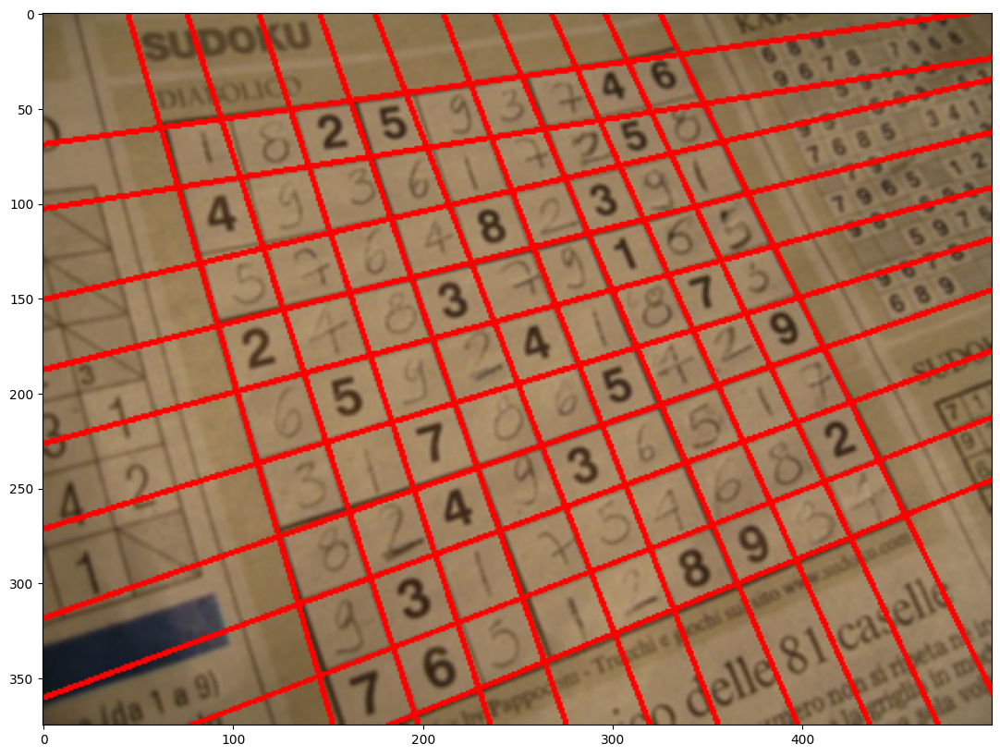

In [18]:
# Implementasi metode Hough Transform pada OpenCV
image = cv.imread('/content/drive/MyDrive/PCVK/GAMBAR/sudoku.jpg')
image = cv.cvtColor(image, cv.COLOR_BGR2RGB)
image_gray = cv.cvtColor(image, cv.COLOR_BGR2GRAY)

# Menerapkan Canny Edge Detection
edges = cv.Canny(image_gray,50,250,apertureSize = 3)

# Dilasi gambar tepi (Canny bisa menemukan kedua tepi pemisah pada grid sebagai tepi yang
# berbeda, dilatasi dapat membuat kedua tepi ini bergabung lagi)
se = np.ones((3,3))
edges = cv.dilate(edges, se)

# Erosi (setelah proses dilasi, garis border menjadi tebal sehingga Hough akan mendeteksi banyak garis)
se = np.ones((3,3))
edges = cv.erode(edges, se)

# Menerapkan  HoughLines dengan fungsi cv2.HoughLines() pada OpenCV
lines = cv.HoughLines(edges,1,np.pi/180,220)

# Menggabungkan garis yang mirip (similar)
rho_threshold = 15
theta_threshold = 0.1

similar_lines = {i : [] for i in range(len(lines))}
for i in range(len(lines)):
  for j in range (len (lines)):
    if i == j:
      continue

    rho_i, theta_i = lines[i][0]
    rho_j, theta_j = lines[j][0]
    if abs(rho_i - rho_j) < rho_threshold and abs (theta_i - theta_j) < theta_threshold:
      similar_lines[i].append(j)

indices = [i for i in range(len(lines))]
indices.sort(key=lambda x: len(similar_lines[x]))

line_flags = len(lines) *[True]
for i in range(len(lines) - 1):
  if not line_flags [indices[i]]:
    continue

  for j in range(i + 1, len(lines)):
    if not line_flags[indices[j]]:
      continue
    rho_i, theta_i = lines[indices[i]][0]
    rho_j, theta_j = lines[indices[j]][0]
    if abs(rho_i - rho_j) < rho_threshold and abs(theta_i - theta_j) < theta_threshold:
      line_flags [indices[j]] = False

filtered_lines = []
for i in range(len(lines)):
  if line_flags[i]:
    filtered_lines.append(lines[i])

for line in filtered_lines:
    rho,theta = line[0]
    a = np.cos(theta)
    b = np.sin(theta)
    x0 = a*rho
    y0 = b*rho
    x1 = int(x0 + 1000*(-b))
    y1 = int(y0 + 1000*(a))
    x2 = int(x0 - 1000*(-b))
    y2 = int(y0 - 1000*(a))
    cv.line(image,(x1,y1),(x2,y2),(255,0,0),2)

plt.figure(figsize = (15,10))
plt.imshow(image)

7. Implementasikan fungsi findContours() pada OpenCV untuk contour detection dengan menggunakan gambar laptop.jpg, sehingga menghasilkan luaran sebagai berikut:

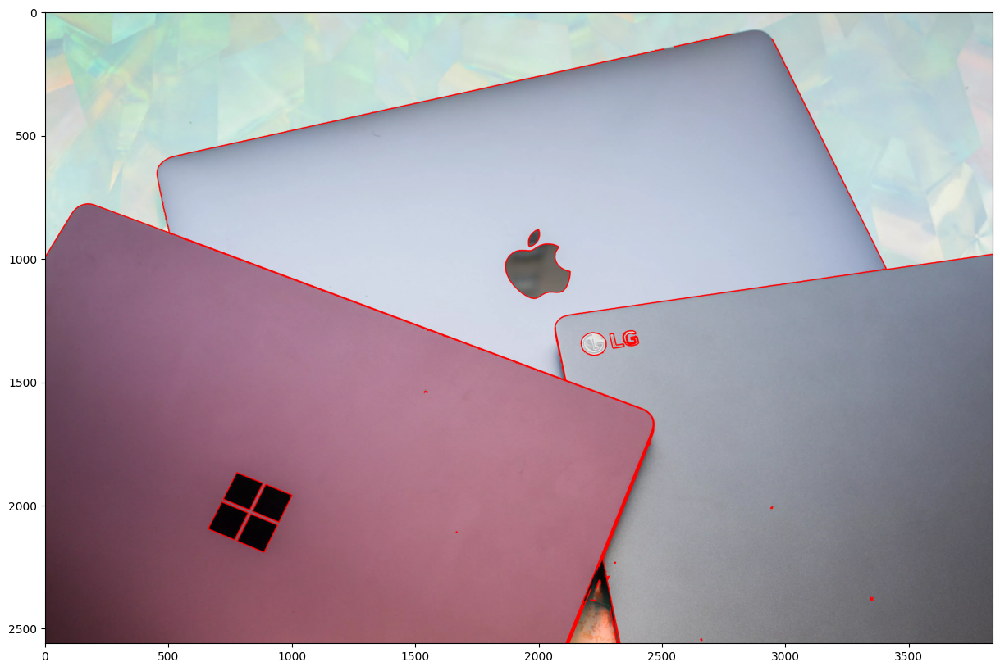

In [19]:
# Implementasi fungsi findContours() pada OpenCV
image = cv.imread('/content/drive/MyDrive/PCVK/GAMBAR/laptop.jpg')
image = cv.cvtColor(image, cv.COLOR_BGR2RGB)
image_gray = cv.cvtColor(image, cv.COLOR_BGR2GRAY)

# Menerapkan Canny Edge Detection
edged = cv.Canny(image_gray, 30, 200)

# Menerapkan fungsi findContours() openCV
contours, hierarchy = cv.findContours(edged,
    cv.RETR_EXTERNAL, cv.CHAIN_APPROX_NONE)
cv.drawContours(image, contours, -1, (255, 0, 0), 3)

plt.figure(figsize = (15,10))
plt.imshow(image)

**D2. Praktikum Feature Matching dan Face Detection**

8. Lakukan Face Detection untuk image object lain yang tersedia pada (/images/facedet). Tampilkan seperti pada contoh berikut.  

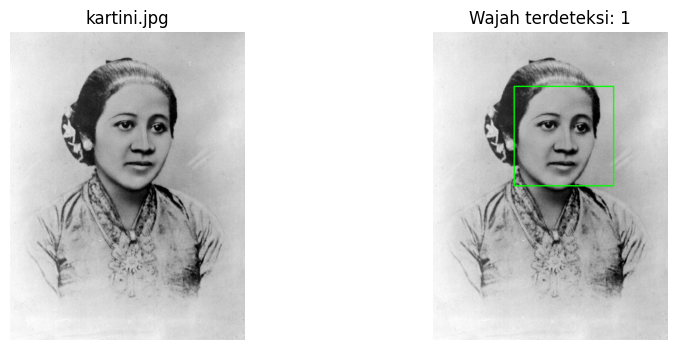

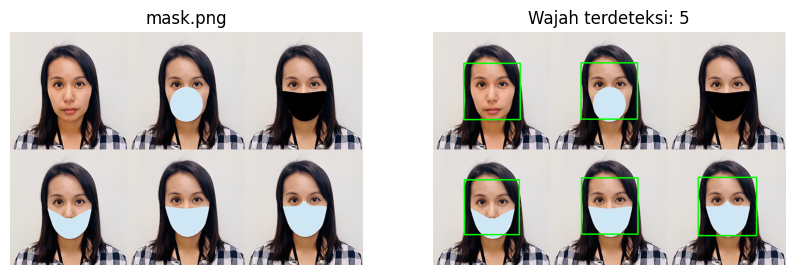

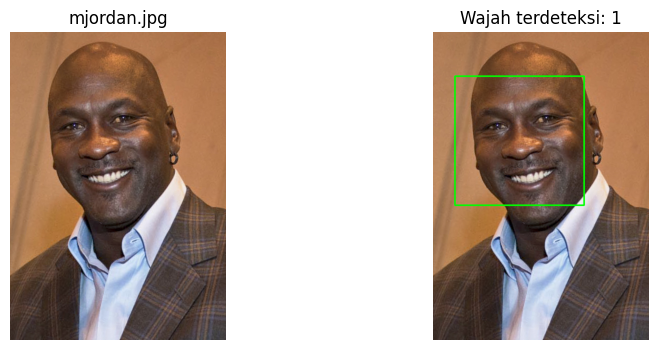

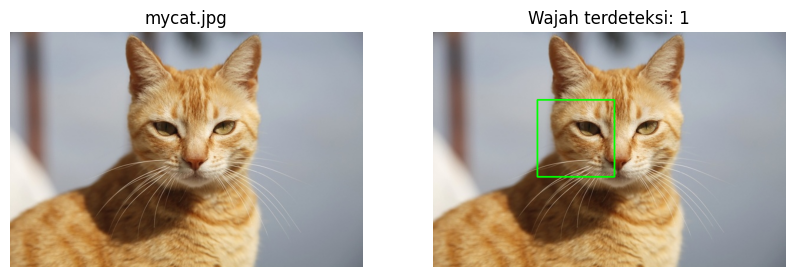

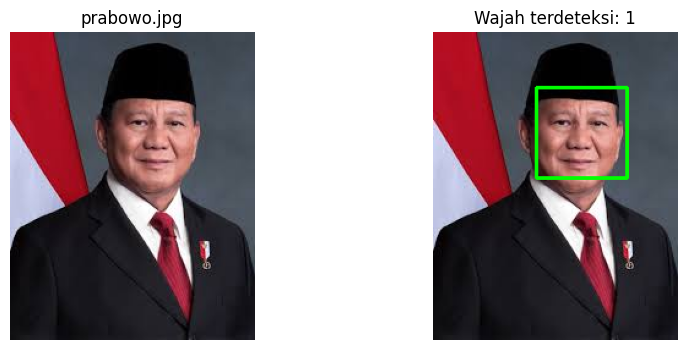

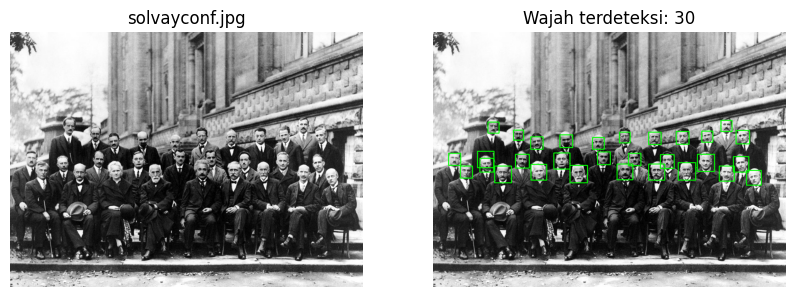

In [23]:
import os, glob
import numpy as np
import cv2
import matplotlib.pyplot as plt

# ==========================================
# 1. LOAD MODEL & DAFTAR GAMBAR
# ==========================================
face_cascade = cv2.CascadeClassifier(
    cv2.data.haarcascades + 'haarcascade_frontalface_default.xml'
)

folder = '/content/drive/MyDrive/PCVK/GAMBAR/facedet'   # sesuaikan path-nya
paths = sorted(
    glob.glob(os.path.join(folder, '*.jpg')) +
    glob.glob(os.path.join(folder, '*.jpeg')) +
    glob.glob(os.path.join(folder, '*.png'))
)

# ==========================================
# 2. PROFIL PARAMETER PER JENIS GAMBAR
# ==========================================
PROFILES = {
    # foto potret / lukisan / kucing: 1 wajah terbesar saja
    'portrait': dict(scale=1.1,  neighbors=6, min_size=(30, 30),
                     single_face=True,  size_filter=False, top_cut=0.0),
    # foto ramai (Solvay): wajah kecil, banyak, buang kotak di tembok
    'crowd':    dict(scale=1.05, neighbors=3, min_size=(15, 15),
                     single_face=False, size_filter=True,  top_cut=0.3),
    # beberapa wajah bermasker: semua kotak dipertahankan
    'multi':    dict(scale=1.1,  neighbors=3, min_size=(40, 40),
                     single_face=False, size_filter=False, top_cut=0.0),
}

# potongan nama file -> profil (selain itu otomatis 'portrait')
FILE_PROFILE = {
    'solvay': 'crowd',
    'mask':   'multi',
}

def get_profile(filename):
    name = filename.lower()
    for key, prof in FILE_PROFILE.items():
        if key in name:
            return PROFILES[prof]
    return PROFILES['portrait']

# ==========================================
# 3. FUNGSI DETEKSI, FILTER, DAN GAMBAR
# ==========================================
def detect_faces(img_rgb, scale, neighbors, min_size):
    gray = cv2.cvtColor(img_rgb, cv2.COLOR_RGB2GRAY)
    return face_cascade.detectMultiScale(
        gray, scaleFactor=scale, minNeighbors=neighbors, minSize=min_size
    )

def filter_boxes(faces, img_shape, single_face, size_filter, top_cut):
    if len(faces) == 0:
        return []
    faces = list(faces)

    if single_face:
        return [max(faces, key=lambda f: f[2] * f[3])]

    if size_filter:
        med = np.median([f[2] for f in faces])
        faces = [f for f in faces if 0.6 * med <= f[2] <= 1.5 * med]

    if top_cut > 0:
        H = img_shape[0]
        faces = [f for f in faces if f[1] > top_cut * H]

    return faces

def draw_boxes(img_rgb, faces):
    out = img_rgb.copy()
    for (x, y, w, h) in faces:
        cv2.rectangle(out, (x, y), (x + w, y + h), (0, 255, 0), 2)
    return out

# ==========================================
# 4. TAMPILKAN: ASLI | HASIL
# ==========================================
for p in paths:
    img = cv2.cvtColor(cv2.imread(p), cv2.COLOR_BGR2RGB)
    prof = get_profile(os.path.basename(p))

    faces = detect_faces(img, prof['scale'], prof['neighbors'], prof['min_size'])
    faces = filter_boxes(faces, img.shape,
                         prof['single_face'], prof['size_filter'], prof['top_cut'])
    result = draw_boxes(img, faces)

    plt.figure(figsize=(10, 4))
    plt.subplot(1, 2, 1); plt.imshow(img);    plt.title(os.path.basename(p)); plt.axis('off')
    plt.subplot(1, 2, 2); plt.imshow(result); plt.title(f'Wajah terdeteksi: {len(faces)}'); plt.axis('off')
    plt.show()

9. Pada soal sebelumnya, wajah kucing tidak bisa dideteksi dengan baik. Lakukan deteksi wajah kucing hingga muncul rectangle pada bagian wajah kucing. Petunjuk pada soal ini, perhatikan pretrained features yang telah disediakan OpenCV. Gunakan xml yang ada jika memang telah disediakan. Jika belum ada, coba cari dengan searching melalui search engines.  

File: /content/drive/MyDrive/PCVK/GAMBAR/facedet/mycat.jpg
Jumlah wajah kucing terdeteksi: 1


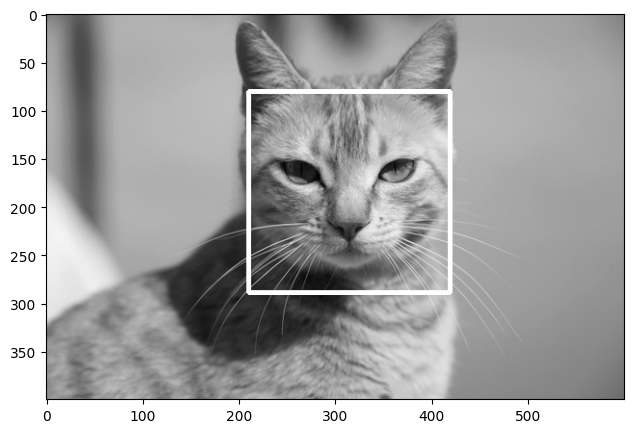

In [24]:
import os, glob
import cv2
import matplotlib.pyplot as plt

# ==========================================
# 1. LOAD CASCADE WAJAH KUCING
# ==========================================
cat_cascade = cv2.CascadeClassifier(
    cv2.data.haarcascades + 'haarcascade_frontalcatface.xml'
)
cat_cascade_ext = cv2.CascadeClassifier(
    cv2.data.haarcascades + 'haarcascade_frontalcatface_extended.xml'
)

# ==========================================
# 2. BACA GAMBAR KUCING
# ==========================================
folder = '/content/drive/MyDrive/PCVK/GAMBAR/facedet'   # sesuaikan path-nya
cat_paths = [p for p in glob.glob(os.path.join(folder, '*'))
             if 'cat' in os.path.basename(p).lower()]
cat_path = cat_paths[0]                                  # atau isi manual nama filenya
print("File:", cat_path)

img = cv2.imread(cat_path)
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

# ==========================================
# 3. DETEKSI WAJAH KUCING
# ==========================================
faces = cat_cascade.detectMultiScale(
    gray, scaleFactor=1.1, minNeighbors=5, minSize=(75, 75)
)

# kalau versi biasa tidak menemukan apa-apa, coba versi extended
if len(faces) == 0:
    faces = cat_cascade_ext.detectMultiScale(
        gray, scaleFactor=1.1, minNeighbors=5, minSize=(75, 75)
    )

print("Jumlah wajah kucing terdeteksi:", len(faces))

# ==========================================
# 4. GAMBAR RECTANGLE (PUTIH) & TAMPILKAN
# ==========================================
result = gray.copy()
for (x, y, w, h) in faces:
    cv2.rectangle(result, (x, y), (x + w, y + h), 255, 3)   # 255 = putih

plt.figure(figsize=(8, 5))
plt.imshow(result, cmap='gray')
plt.axis('on')
plt.show()

10. Cobakan juga untuk eyes detection pada wajah Pak Prabowo:

File: /content/drive/MyDrive/PCVK/GAMBAR/facedet/prabowo.jpg
Jumlah wajah terdeteksi: 1
Jumlah mata terdeteksi: 2


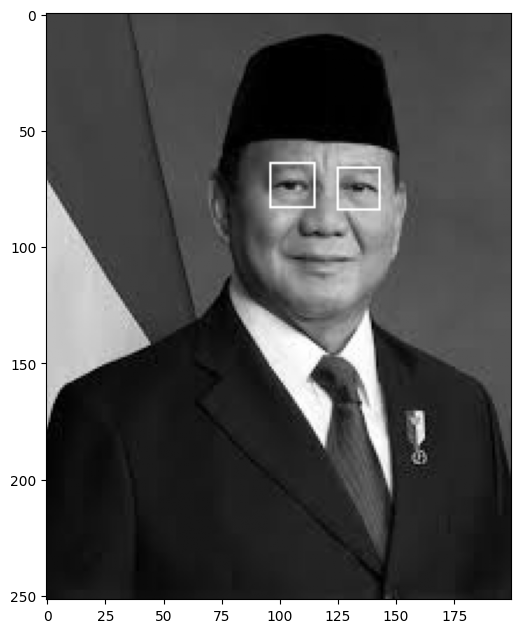

In [26]:
import os, glob
import cv2
import matplotlib.pyplot as plt

# ==========================================
# 1. LOAD CASCADE
# ==========================================
face_cascade = cv2.CascadeClassifier(
    cv2.data.haarcascades + 'haarcascade_frontalface_default.xml'
)
eye_cascade = cv2.CascadeClassifier(
    cv2.data.haarcascades + 'haarcascade_eye.xml'
)
eye_cascade_alt = cv2.CascadeClassifier(
    cv2.data.haarcascades + 'haarcascade_eye_tree_eyeglasses.xml'
)

# ==========================================
# 2. BACA GAMBAR & PERBESAR
# ==========================================
folder = '/content/drive/MyDrive/PCVK/GAMBAR/facedet'   # sesuaikan path-nya
cands = [p for p in glob.glob(os.path.join(folder, '*'))
         if 'prabowo' in os.path.basename(p).lower()]
img_path = cands[0]       # atau isi manual: os.path.join(folder, 'namafile.jpg')
print("File:", img_path)

img = cv2.imread(img_path)
gray_orig = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

SCALE = 3                                                # perbesar 3x supaya fitur mata terbaca
gray = cv2.resize(gray_orig, None, fx=SCALE, fy=SCALE, interpolation=cv2.INTER_CUBIC)
gray = cv2.equalizeHist(gray)                            # perjelas kontras

# ==========================================
# 3. DETEKSI WAJAH (PARAMETER LEBIH LONGGAR)
# ==========================================
faces = face_cascade.detectMultiScale(gray, scaleFactor=1.05, minNeighbors=3, minSize=(60, 60))
print("Jumlah wajah terdeteksi:", len(faces))

if len(faces) > 0:
    faces = [max(faces, key=lambda f: f[2] * f[3])]      # wajah terbesar
else:
    # fallback: kalau wajah tidak ketemu, cari mata di seluruh gambar
    faces = [(0, 0, gray.shape[1], gray.shape[0])]
    print("Wajah tidak ketemu -> cari mata di seluruh gambar")

# ==========================================
# 4. DETEKSI MATA DI ROI WAJAH
# ==========================================
result = gray_orig.copy()
total_eyes = 0

for (x, y, w, h) in faces:
    # mata ada di sekitar 15%-60% tinggi wajah
    y1, y2 = y + int(h * 0.15), y + int(h * 0.60)
    roi = gray[y1:y2, x:x + w]

    eyes = eye_cascade.detectMultiScale(roi, scaleFactor=1.03, minNeighbors=2, minSize=(20, 20))
    if len(eyes) == 0:                                   # coba cascade alternatif
        eyes = eye_cascade_alt.detectMultiScale(roi, scaleFactor=1.03, minNeighbors=2, minSize=(20, 20))

    # ambil maksimal 2 mata terbesar
    eyes = sorted(eyes, key=lambda e: e[2] * e[3], reverse=True)[:2]

    for (ex, ey, ew, eh) in eyes:
        # kembalikan koordinat ke ukuran gambar asli
        x1 = int((x + ex) / SCALE);        y1_ = int((y1 + ey) / SCALE)
        x2 = int((x + ex + ew) / SCALE);   y2_ = int((y1 + ey + eh) / SCALE)
        cv2.rectangle(result, (x1, y1_), (x2, y2_), 255, 1)   # putih
        total_eyes += 1

print("Jumlah mata terdeteksi:", total_eyes)

# ==========================================
# 5. TAMPILKAN
# ==========================================
plt.figure(figsize=(6, 8))
plt.imshow(result, cmap='gray')
plt.axis('on')
plt.show()

11. Lakukan deteksi senyuman pada gambar people:

Jumlah senyum terdeteksi: 4


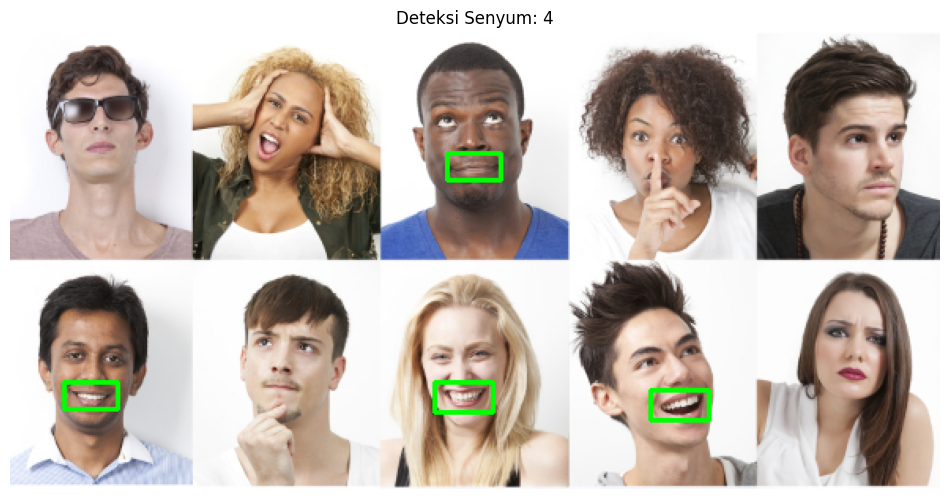

In [29]:
import os, glob
import cv2
import matplotlib.pyplot as plt

face_cascade = cv2.CascadeClassifier(cv2.data.haarcascades + 'haarcascade_frontalface_default.xml')
smile_cascade = cv2.CascadeClassifier(cv2.data.haarcascades + 'haarcascade_smile.xml')

folder = '/content/drive/MyDrive/PCVK/GAMBAR/facedet'
img_path = [p for p in glob.glob(os.path.join(folder, '*'))
            if 'people' in os.path.basename(p).lower()][0]

img = cv2.cvtColor(cv2.imread(img_path), cv2.COLOR_BGR2RGB)
gray = cv2.cvtColor(img, cv2.COLOR_RGB2GRAY)

# wajah hanya dipakai sebagai area pencarian (tidak digambar)
faces = face_cascade.detectMultiScale(gray, scaleFactor=1.05, minNeighbors=5, minSize=(50, 50))

result = img.copy()
count = 0

for (x, y, w, h) in faces:
    # area mulut: 55%-100% tinggi wajah
    y0 = y + int(h * 0.55)
    roi = gray[y0:y + h, x:x + w]
    roi = cv2.resize(roi, None, fx=2, fy=2, interpolation=cv2.INTER_CUBIC)

    smiles = smile_cascade.detectMultiScale(roi, scaleFactor=1.3,
                                            minNeighbors=15, minSize=(30, 15))
    if len(smiles) > 0:
        sx, sy, sw, sh = max(smiles, key=lambda s: s[2] * s[3])
        sx, sy, sw, sh = sx // 2, sy // 2, sw // 2, sh // 2

        # buang kotak yang terlalu sempit/tinggi (bukan bentuk mulut tersenyum)
        if sw / sh < 1.5:
            continue

        cv2.rectangle(result, (x + sx, y0 + sy), (x + sx + sw, y0 + sy + sh), (0, 255, 0), 2)
        count += 1

print("Jumlah senyum terdeteksi:", count)

plt.figure(figsize=(12, 6))
plt.imshow(result)
plt.axis('off')
plt.title(f'Deteksi Senyum: {count}')
plt.show()

12.  Lakukan Blurring pada bagian wajah yang terdeteksi. Berikut contoh keluaran yang diharapkan. Petunjuk: anda dapat menggunakan cv.medianBlur untuk melakukan Blurring

File: /content/drive/MyDrive/PCVK/GAMBAR/facedet/mjordan.jpg
Jumlah wajah terdeteksi: 1


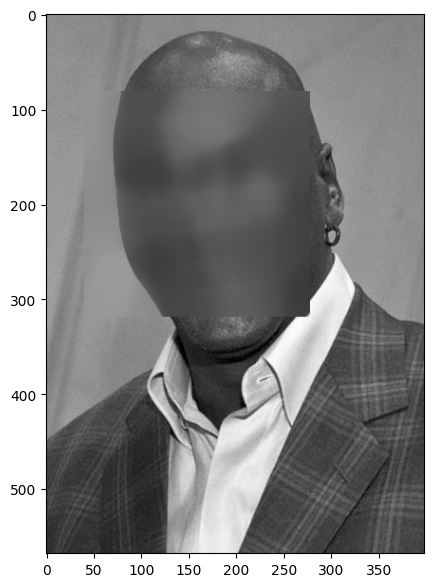

In [30]:
import os, glob
import cv2
import matplotlib.pyplot as plt

# ==========================================
# 1. LOAD CASCADE WAJAH
# ==========================================
face_cascade = cv2.CascadeClassifier(
    cv2.data.haarcascades + 'haarcascade_frontalface_default.xml'
)

# ==========================================
# 2. BACA GAMBAR (grayscale seperti contoh soal)
# ==========================================
folder = '/content/drive/MyDrive/PCVK/GAMBAR/facedet'   # sesuaikan path-nya
img_path = [p for p in glob.glob(os.path.join(folder, '*'))
            if 'mjordan' in os.path.basename(p).lower()][0]
print("File:", img_path)

img = cv2.imread(img_path)
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

# ==========================================
# 3. DETEKSI WAJAH
# ==========================================
faces = face_cascade.detectMultiScale(gray, scaleFactor=1.1, minNeighbors=6, minSize=(30, 30))

# foto potret: ambil wajah terbesar saja (buang kotak nyasar di kerah)
if len(faces) > 0:
    faces = [max(faces, key=lambda f: f[2] * f[3])]
print("Jumlah wajah terdeteksi:", len(faces))

# ==========================================
# 4. BLUR AREA WAJAH DENGAN medianBlur
# ==========================================
result = gray.copy()

for (x, y, w, h) in faces:
    roi = result[y:y + h, x:x + w]

    # ukuran kernel harus ganjil; dibuat proporsional dengan ukuran wajah
    k = (w // 4) | 1
    blurred = cv2.medianBlur(roi, k)

    result[y:y + h, x:x + w] = blurred

# ==========================================
# 5. TAMPILKAN
# ==========================================
plt.figure(figsize=(5, 7))
plt.imshow(result, cmap='gray')
plt.axis('on')
plt.show()

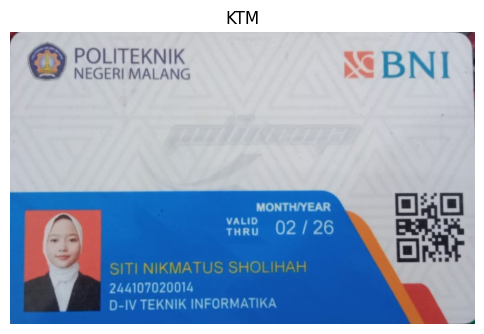

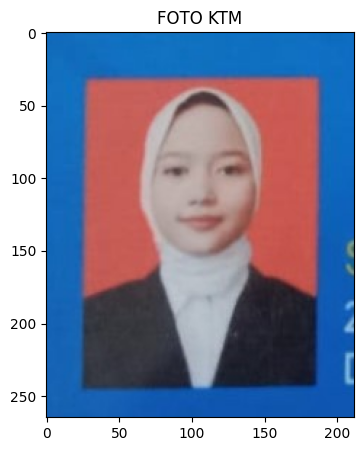

Keypoint KTM: 6746 | Keypoint scene: 6746
Good matches: 6746
KTM terdeteksi. Inlier RANSAC: 6746


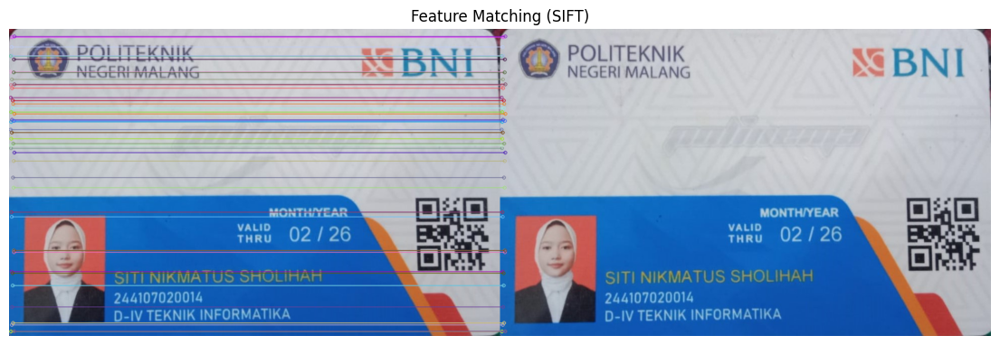

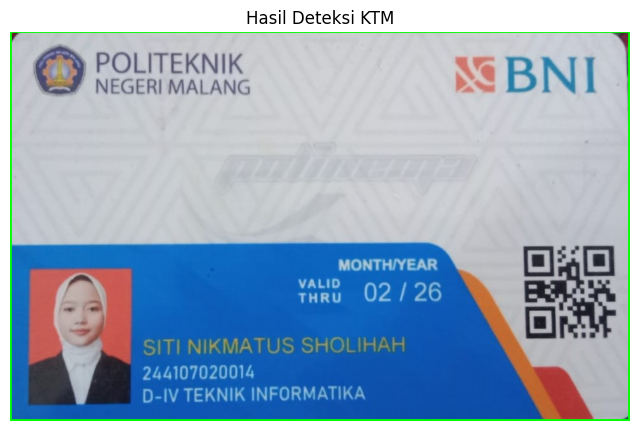

In [35]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

folder     = '/content/drive/MyDrive/PCVK/GAMBAR/'
ktm_path   = folder + 'KTM NISHO.jpeg'
scene_path = folder + 'KTM NISHO.jpeg'          # ganti ke KTM1a / KTM1b / KTM1c kalau mau

# ==========================================
# a. TAMPILKAN KTM
# ==========================================
ktm = cv2.imread(ktm_path)
assert ktm is not None, "KTM tidak terbaca, cek path/nama file"

plt.figure(figsize=(6, 4))
plt.imshow(cv2.cvtColor(ktm, cv2.COLOR_BGR2RGB))
plt.title('KTM'); plt.axis('off'); plt.show()

# ==========================================
# b. CROP FOTO KTM (latar merah)
# ==========================================
hsv = cv2.cvtColor(ktm, cv2.COLOR_BGR2HSV)
mask = cv2.inRange(hsv, (0, 120, 80), (10, 255, 255)) | \
       cv2.inRange(hsv, (170, 120, 80), (180, 255, 255))
mask = cv2.morphologyEx(mask, cv2.MORPH_CLOSE, np.ones((7, 7), np.uint8))

contours, _ = cv2.findContours(mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)

best = None
for c in contours:
    x, y, w, h = cv2.boundingRect(c)
    if w * h > 500 and 0.6 < w / h < 1.0:
        if best is None or w * h > best[2] * best[3]:
            best = (x, y, w, h)

foto = None
if best is not None:
    x, y, w, h = best
    foto = ktm[y:y + h, x:x + w]
else:
    face_cascade = cv2.CascadeClassifier(cv2.data.haarcascades + 'haarcascade_frontalface_default.xml')
    gray = cv2.cvtColor(ktm, cv2.COLOR_BGR2GRAY)
    faces = face_cascade.detectMultiScale(gray, 1.1, 4)
    if len(faces) > 0:
        fx, fy, fw, fh = max(faces, key=lambda f: f[2] * f[3])
        foto = ktm[max(0, fy - fh // 2): fy + int(fh * 2), max(0, fx - fw // 2): fx + int(fw * 1.5)]

if foto is not None:
    plt.figure(figsize=(4, 5))
    plt.imshow(cv2.cvtColor(foto, cv2.COLOR_BGR2RGB))
    plt.title('FOTO KTM'); plt.axis('on'); plt.show()
else:
    print("Foto KTM tidak ditemukan, sesuaikan rentang warna merah pada inRange")

# ==========================================
# c. DETEKSI KTM DENGAN FEATURE MATCHING (SIFT + Homography)
# ==========================================
scene = cv2.imread(scene_path)
assert scene is not None, "Scene tidak terbaca, cek nama file"

clahe = cv2.createCLAHE(clipLimit=3.0, tileGridSize=(8, 8))
sift  = cv2.SIFT_create(contrastThreshold=0.01, edgeThreshold=20)

g_ktm   = clahe.apply(cv2.cvtColor(ktm,   cv2.COLOR_BGR2GRAY))
g_scene = clahe.apply(cv2.cvtColor(scene, cv2.COLOR_BGR2GRAY))

kp1, des1 = sift.detectAndCompute(g_ktm, None)
kp2, des2 = sift.detectAndCompute(g_scene, None)
print("Keypoint KTM:", len(kp1), "| Keypoint scene:", len(kp2))

bf = cv2.BFMatcher(cv2.NORM_L2)
matches = bf.knnMatch(des1, des2, k=2)
good = [m[0] for m in matches if len(m) == 2 and m[0].distance < 0.75 * m[1].distance]
print("Good matches:", len(good))

result = scene.copy()
MIN_MATCH = 10

if len(good) >= MIN_MATCH:
    src = np.float32([kp1[m.queryIdx].pt for m in good]).reshape(-1, 1, 2)
    dst = np.float32([kp2[m.trainIdx].pt for m in good]).reshape(-1, 1, 2)

    H, inliers = cv2.findHomography(src, dst, cv2.RANSAC, 5.0)
    if H is not None:
        h, w = g_ktm.shape
        corners = np.float32([[0, 0], [0, h - 1], [w - 1, h - 1], [w - 1, 0]]).reshape(-1, 1, 2)
        box = cv2.perspectiveTransform(corners, H)
        cv2.polylines(result, [np.int32(box)], True, (0, 255, 0), 4)
        print("KTM terdeteksi. Inlier RANSAC:", int(inliers.sum()))
    else:
        print("Homography gagal dihitung")
else:
    print("KTM tidak terdeteksi (match kurang dari", MIN_MATCH, ")")

vis = cv2.drawMatches(ktm, kp1, scene, kp2, good[:50], None,
                      flags=cv2.DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS)

plt.figure(figsize=(14, 6)); plt.imshow(cv2.cvtColor(vis, cv2.COLOR_BGR2RGB))
plt.title('Feature Matching (SIFT)'); plt.axis('off'); plt.show()

plt.figure(figsize=(8, 6)); plt.imshow(cv2.cvtColor(result, cv2.COLOR_BGR2RGB))
plt.title('Hasil Deteksi KTM'); plt.axis('off'); plt.show()